<a href="https://colab.research.google.com/github/stevenpanchi41/PRACTICA-3-PERCEPTRON/blob/main/Practica_03_Perceptron_.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Práctica 03 — El Perceptrón
**Inteligencia Artificial**

Nombre: Steven Panchi

fecha: 21/11/2026



## Fase 1. Exploración del dataset
**Pregunta 1.a:** Cada fila de `X` representa un punto con dos variables; `y` es su clase. Es binaria porque solo existen las etiquetas -1 y +1.

Instancias: 23 | Variables: 2 | Clases: 2
Clase -1: 14 | Clase +1: 9


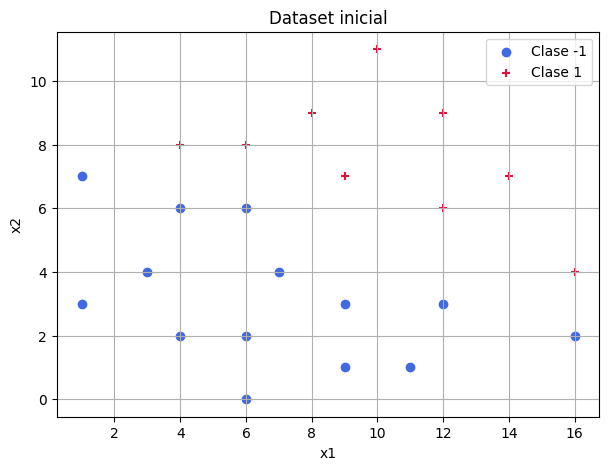

In [1]:
import random
import matplotlib.pyplot as plt

X = [[1,7],[1,3],[3,4],[4,6],[4,2],[6,6],[6,2],[6,0],[7,4],[9,3],[9,1],[11,1],[12,3],[16,2],[4,8],[6,8],[8,9],[9,7],[10,11],[12,9],[12,6],[14,7],[16,4]]
y = [-1]*14 + [1]*9
print('Instancias:',len(X),'| Variables:',len(X[0]),'| Clases:',len(set(y)))
print('Clase -1:',y.count(-1),'| Clase +1:',y.count(1))

def plot_points(X,y,title):
    for label,marker,color in [(-1,'o','royalblue'),(1,'+','crimson')]:
        pts=[p for p,c in zip(X,y) if c==label]
        plt.scatter([p[0] for p in pts],[p[1] for p in pts],marker=marker,color=color,label=f'Clase {label}')
    plt.xlabel('x1');plt.ylabel('x2');plt.title(title);plt.grid(True);plt.legend()

plt.figure(figsize=(7,5));plot_points(X,y,'Dataset inicial');plt.show()

**Pregunta 1.b:** Los grupos parecen separables por una recta inclinada: los puntos +1 están generalmente por encima de los -1.

## Fase 2. Fundamentos
**2.a:** Se usan tres pesos porque uno corresponde al sesgo (`w0`) y los otros dos a las entradas. El sesgo permite desplazar la recta.

**2.b:** Las etiquetas -1 y +1 son coherentes con el escalón bipolar y permiten expresar la corrección como `y - predicción`.

**2.c:** `z` es una suma numérica ponderada; la activación convierte esa suma en una etiqueta de clase.

In [2]:
random.seed(42)
def initialize_weights():
    return [random.uniform(-0.5,0.5) for _ in range(3)]

def activation(z):
    return 1 if z >= 0 else -1

def perceptron_compute(x,w):
    z=w[0]+w[1]*x[0]+w[2]*x[1]
    return activation(z)

w_demo=initialize_weights()
print('Pesos de prueba:',w_demo)
for i in [0,14,22]:
    print('Punto:',X[i],'Real:',y[i],'Predicción:',perceptron_compute(X[i],w_demo))

Pesos de prueba: [0.13942679845788375, -0.47498924477733306, -0.22497068163088074]
Punto: [1, 7] Real: -1 Predicción: -1
Punto: [4, 8] Real: 1 Predicción: -1
Punto: [16, 4] Real: 1 Predicción: -1


## Fase 3. Frontera de decisión
**3.a:** La recta es el conjunto de puntos donde la suma ponderada vale cero. Los pesos aleatorios generan una frontera inicialmente arbitraria.

**3.b:** No se espera que una frontera aleatoria clasifique todos los datos porque todavía no ha aprendido de los errores.

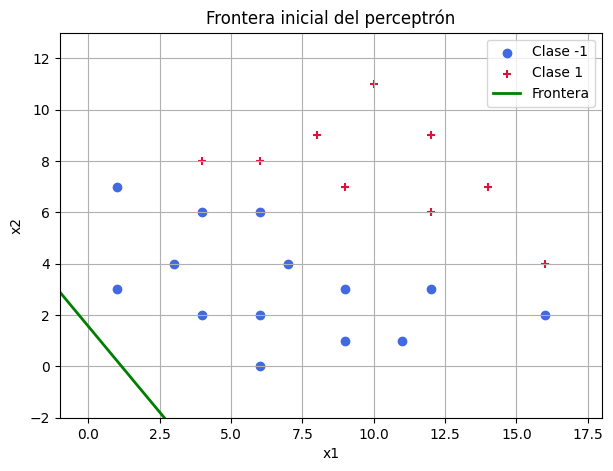

In [3]:
def perceptron_plot(X,y,w,title):
    plt.figure(figsize=(7,5))
    plot_points(X,y,title)
    xmin=min(p[0] for p in X)-2
    xmax=max(p[0] for p in X)+2
    if abs(w[2])>1e-12:
        xs=[xmin,xmax]
        ys=[-(w[0]+w[1]*xx)/w[2] for xx in xs]
        plt.plot(xs,ys,color='green',linewidth=2,label='Frontera')
    elif abs(w[1])>1e-12:
        plt.axvline(-w[0]/w[1],color='green',linewidth=2,label='Frontera')
    else:
        print('No existe una frontera definida: ambos pesos de entrada son cero.')
    plt.xlim(xmin,xmax)
    plt.ylim(min(p[1] for p in X)-2,max(p[1] for p in X)+2)
    plt.legend();plt.show()

w_initial=initialize_weights()
perceptron_plot(X,y,w_initial,'Frontera inicial del perceptrón')

## Fase 4. Entrenamiento
**4.a:** El límite de épocas evita entrenar indefinidamente cuando no se alcanza una separación perfecta.

**4.b:** Una tasa de error cero significa que todas las instancias de entrenamiento fueron clasificadas correctamente.

**4.c:** Se guardan copias de pesos para conservar cada estado histórico; de lo contrario, todos podrían mostrar los últimos valores.

In [4]:
def perceptron_learning(X,y,w,lr,max_epochs):
    weights=w.copy()
    W_values=[weights.copy()]
    E_values=[]
    updates=0
    for epoch in range(max_epochs):
        for x,target in zip(X,y):
            prediction=perceptron_compute(x,weights)
            if prediction!=target:
                difference=target-prediction
                weights[0]+=lr*difference
                weights[1]+=lr*difference*x[0]
                weights[2]+=lr*difference*x[1]
                updates+=1
        errors=sum(perceptron_compute(x,weights)!=target for x,target in zip(X,y))
        E_values.append(errors/len(X))
        W_values.append(weights.copy())
        if errors==0:
            break
    return weights,len(E_values),updates,W_values,E_values

print('Función de aprendizaje preparada.')

Función de aprendizaje preparada.


## Fase 5. Entrenamiento con lr = 0.5
**5.a:** La convergencia se comprueba cuando el último error registrado en `E_values` es cero.

**5.b:** Si converge, la recta final separa las clases, a diferencia de la frontera inicial arbitraria.

Pesos iniciales: [0.3921795677048454, -0.41306116737058385, -0.07807818031472957]
Pesos finales: [-76.60782043229516, 3.5869388326294143, 8.92192181968527]
Épocas: 114
Actualizaciones: 427
Error final: 0.0
¿Convergió? True


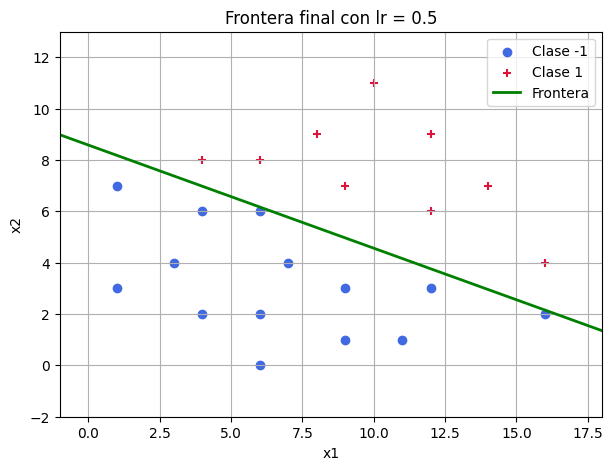

In [5]:
w=initialize_weights()
final_w,epochs,updates,W_values,E_values=perceptron_learning(X,y,w,lr=0.5,max_epochs=1000)
print('Pesos iniciales:',w)
print('Pesos finales:',final_w)
print('Épocas:',epochs)
print('Actualizaciones:',updates)
print('Error final:',E_values[-1])
print('¿Convergió?',E_values[-1]==0)
perceptron_plot(X,y,final_w,'Frontera final con lr = 0.5')

## Fase 6. Nuevas instancias
**6.a:** Se comparan las predicciones con el lado de la frontera en que queda cada punto.

**6.b:** Los puntos próximos a la recta son los más discutibles: pequeños cambios en la frontera pueden cambiar su clasificación.

Instancia       Salida predicha
[5, 5]          -1
[10, 6]         +1
[6, 10]         +1


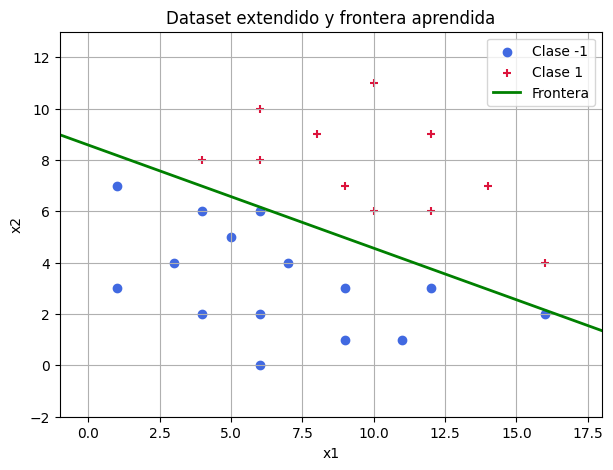

In [6]:
X_test=[[5,5],[10,6],[6,10]]
predictions=[perceptron_compute(x,final_w) for x in X_test]
print(f"{'Instancia':<15} Salida predicha")
for x,pred in zip(X_test,predictions):
    print(f'{str(x):<15} {pred:+d}')
X_extended=[p.copy() for p in X]+[p.copy() for p in X_test]
y_extended=y.copy()+predictions.copy()
perceptron_plot(X_extended,y_extended,final_w,'Dataset extendido y frontera aprendida')

## Fase 7. Evolución de la frontera
**7.a:** La frontera rota o se desplaza conforme cambian los pesos. Los cambios pueden ser bruscos cuando se corrigen errores.

**7.b:** La pendiente es `-w1/w2`, por lo que ambos pesos influyen en la inclinación; `w0` desplaza la recta.

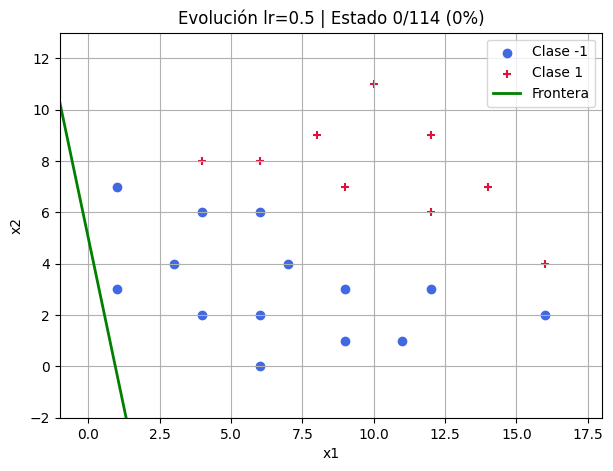

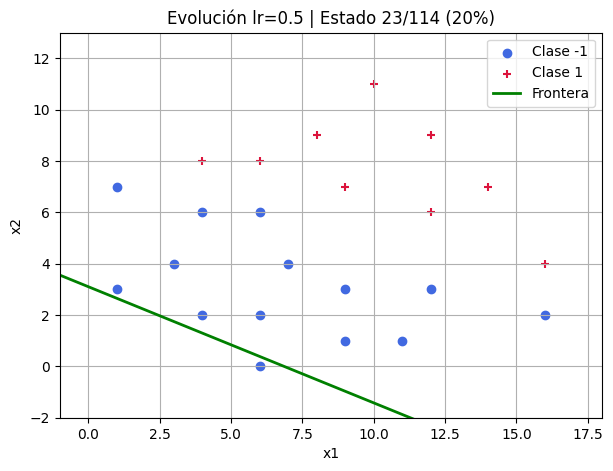

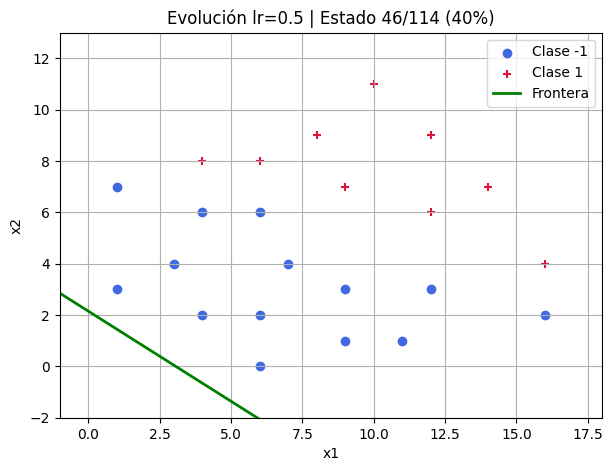

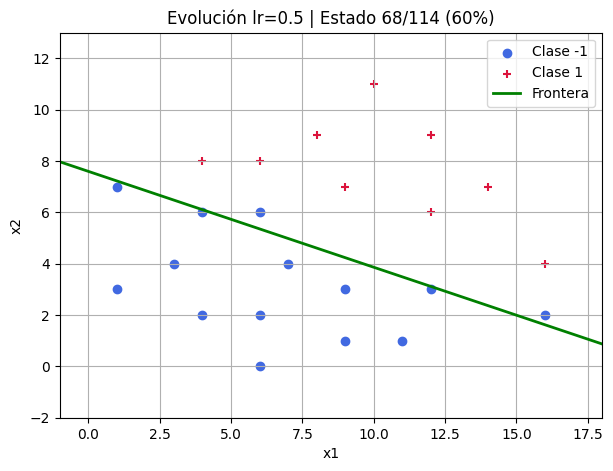

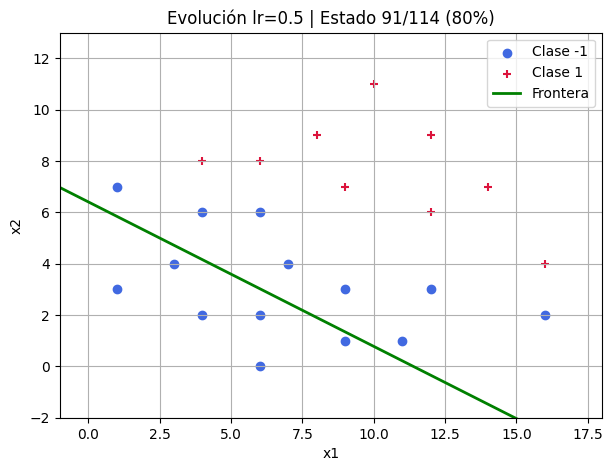

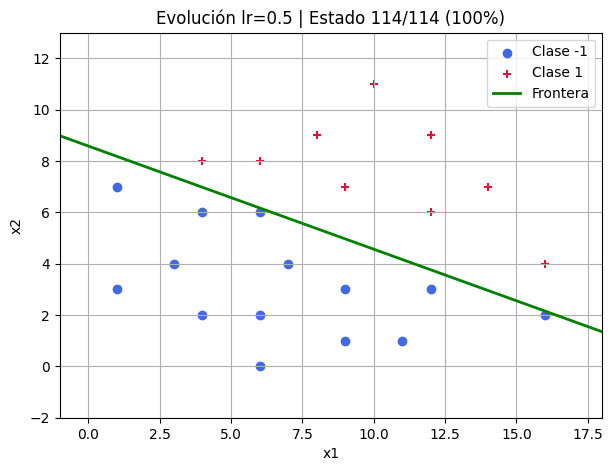

In [7]:
def plot_six_states(X,y,W_values,title):
    n=len(W_values)-1
    if n<5:
        indices=list(range(n+1))
    else:
        indices=sorted(set(round(n*p) for p in [0,0.2,0.4,0.6,0.8,1]))
    for idx in indices:
        percent=round(100*idx/n) if n else 0
        perceptron_plot(X,y,W_values[idx],f'{title} | Estado {idx}/{n} ({percent}%)')

plot_six_states(X,y,W_values,'Evolución lr=0.5')

## Fase 8. Evolución del error
**8.a:** El error puede subir o mantenerse en ciertas épocas porque una actualización que corrige un punto puede afectar a otros.

**8.b:** Error cero implica clasificación correcta en el conjunto de entrenamiento, pero no garantiza precisión perfecta con datos futuros.

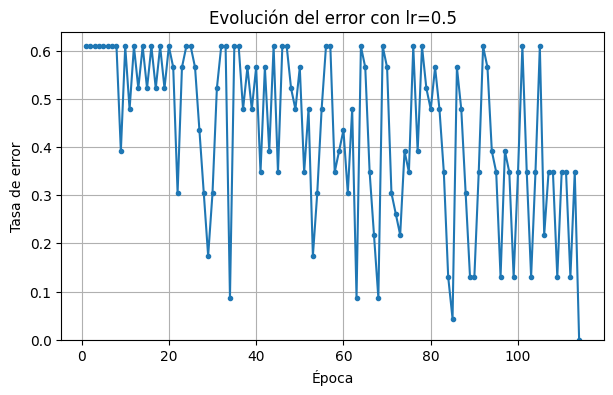

In [8]:
def plot_error(E_values,title):
    plt.figure(figsize=(7,4))
    plt.plot(range(1,len(E_values)+1),E_values,marker='.',linewidth=1.5)
    plt.xlabel('Época');plt.ylabel('Tasa de error');plt.title(title)
    plt.grid(True);plt.ylim(bottom=0);plt.show()

plot_error(E_values,'Evolución del error con lr=0.5')

## Fase 9. Comparación de tasas
**9.a:** Se deben usar los mismos pesos iniciales para que la comparación refleje la tasa de aprendizaje y no una diferencia de inicio.

**9.b:** La tasa que necesite menos épocas no es necesariamente la mejor en todos los problemas; también importa la estabilidad y generalización.

**9.c:** Los pesos finales pueden ser diferentes porque distintas rectas pueden separar correctamente las mismas clases.

lr     Épocas    Actualizaciones   Error final   Pesos finales
0.3    73        257               0.0000        [-31.07, 0.919, 4.205]
0.5    263       897               0.0000        [-133.47, 5.719, 16.005]
0.8    283       920               0.0000        [-214.87, 9.319, 25.605]


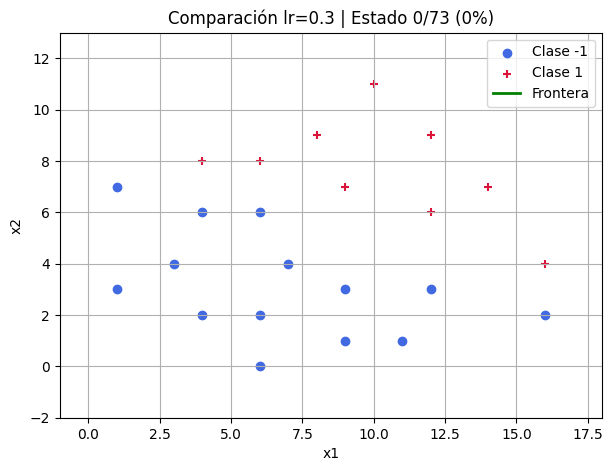

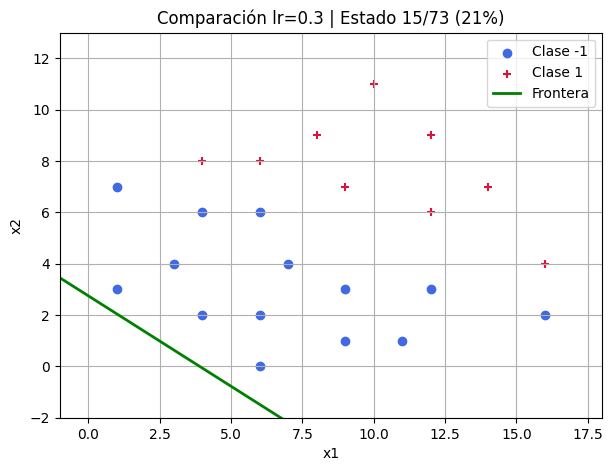

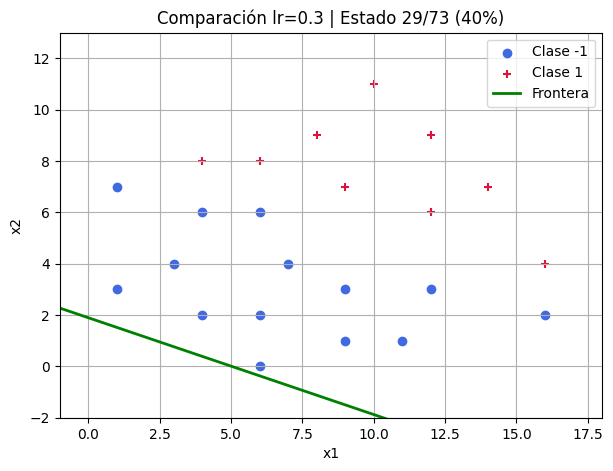

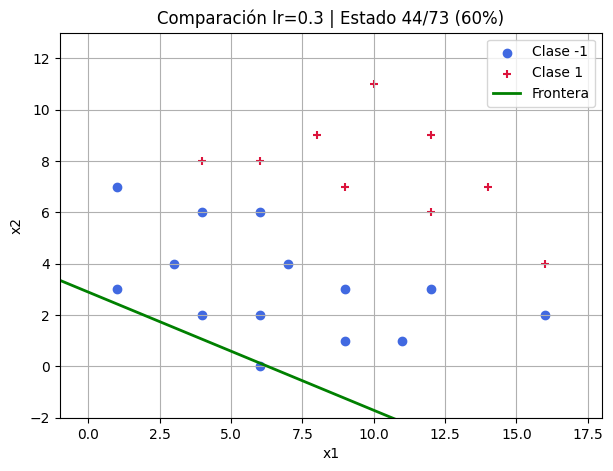

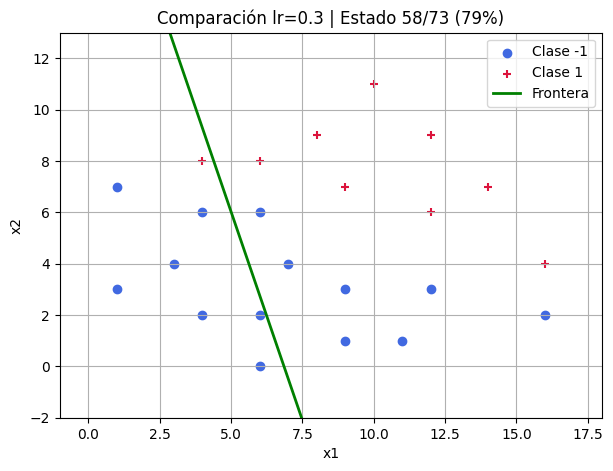

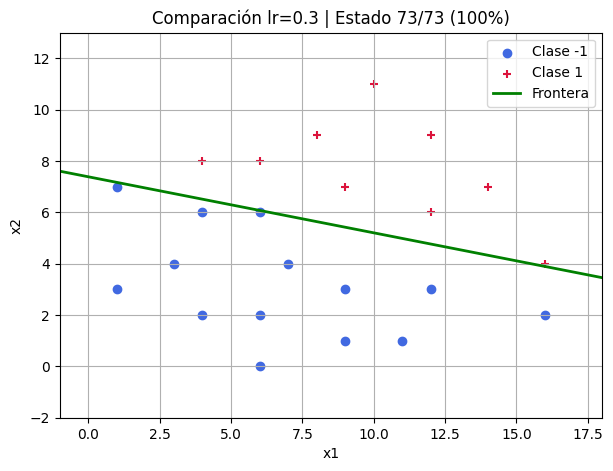

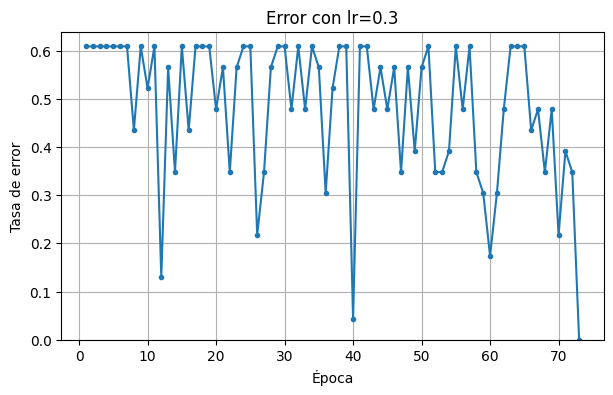

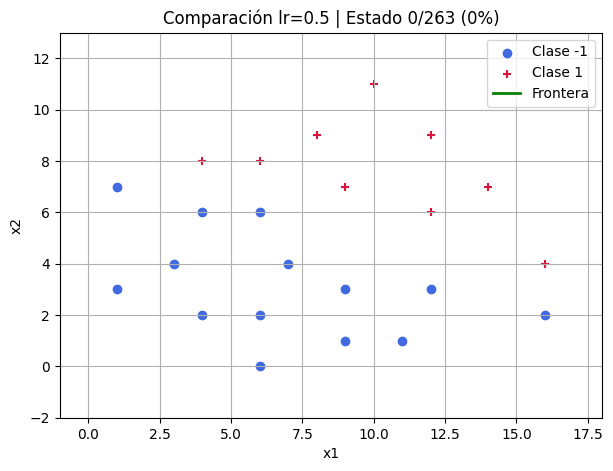

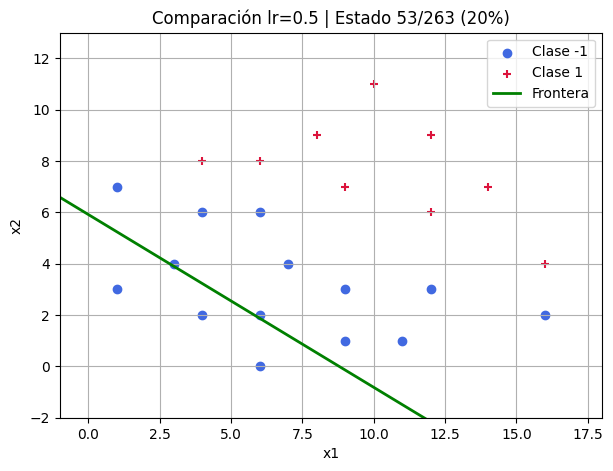

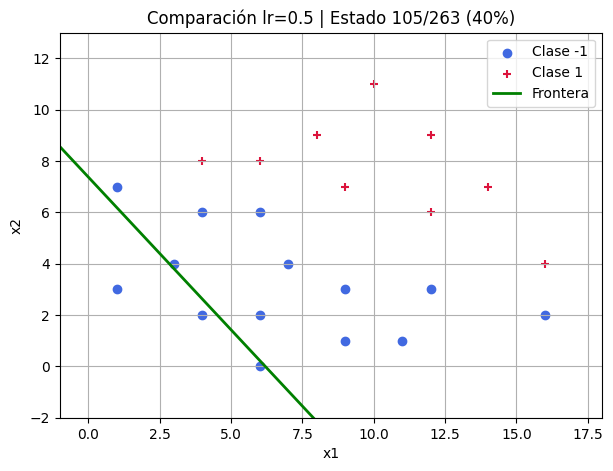

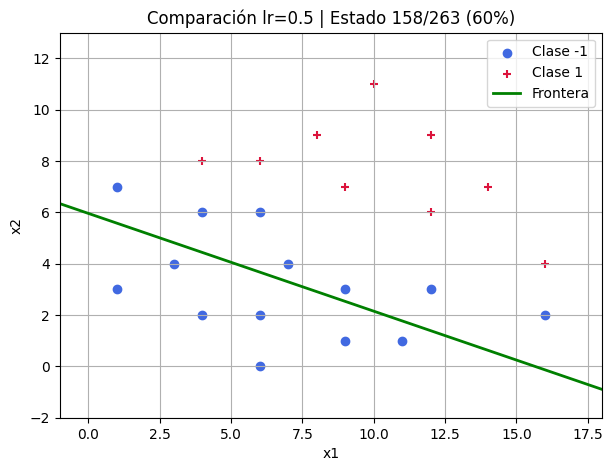

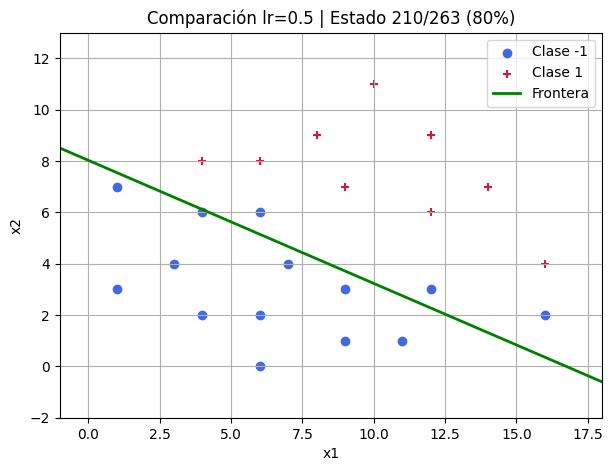

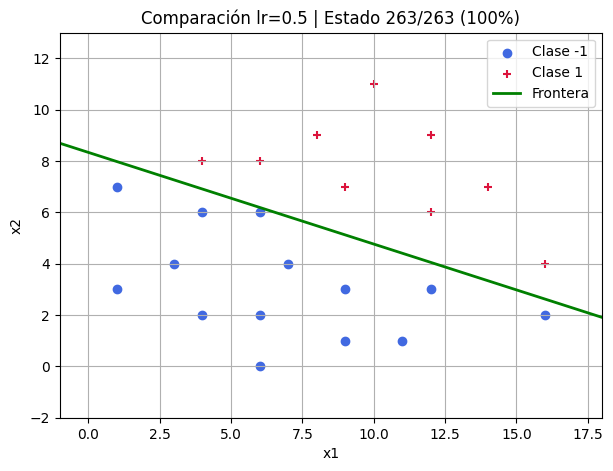

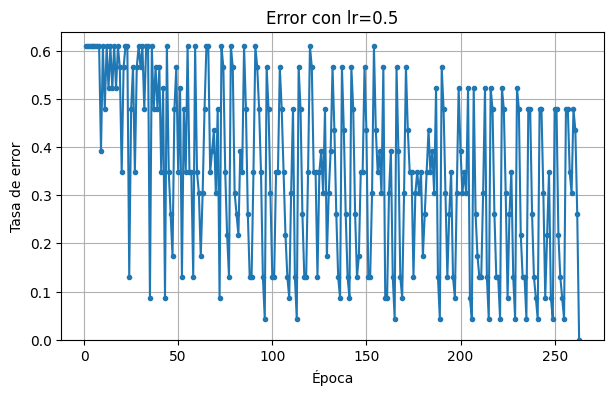

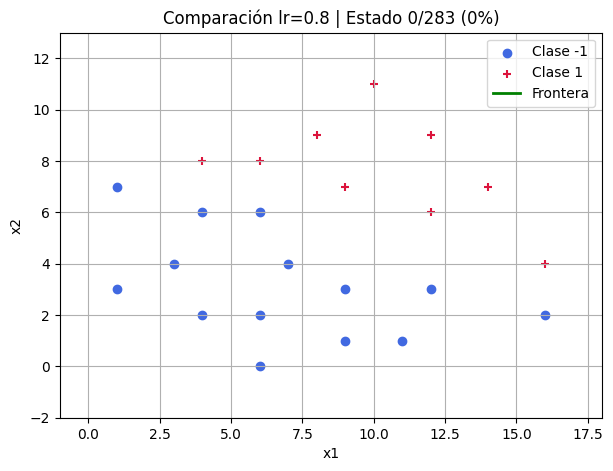

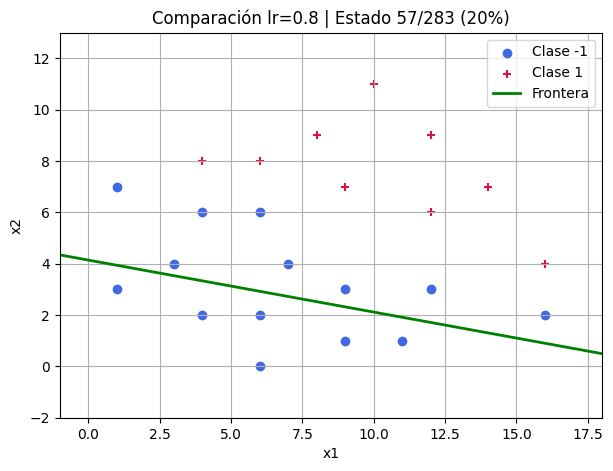

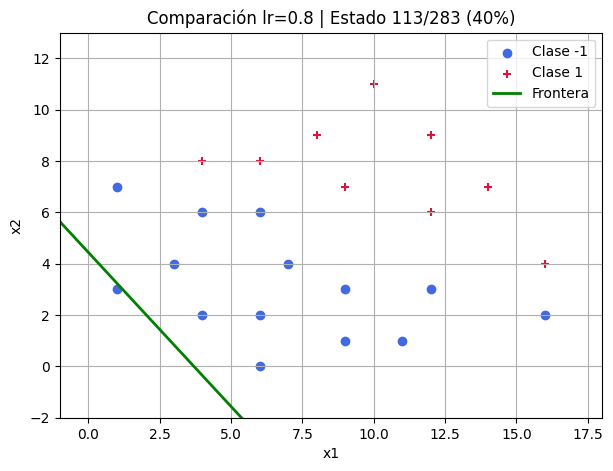

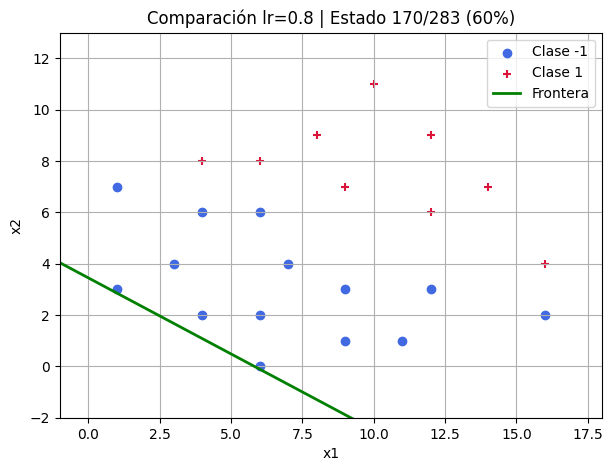

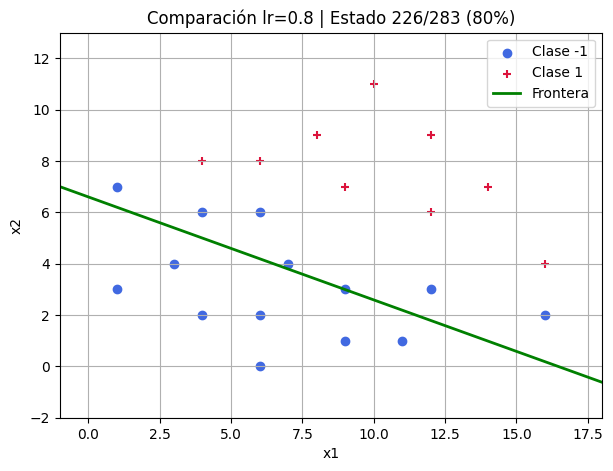

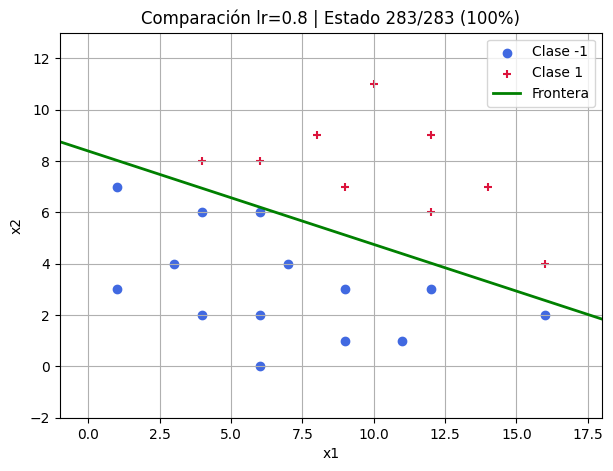

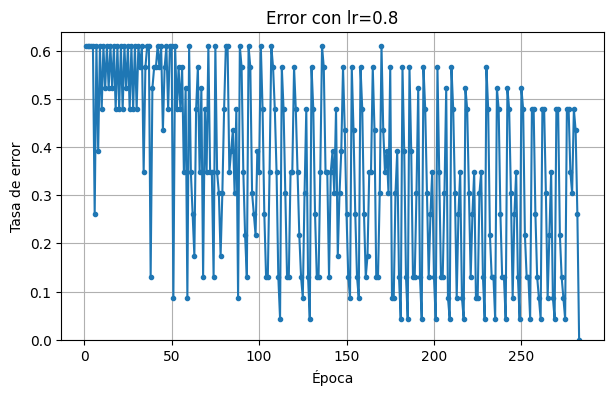

Menor número de épocas: 0.3
¿Todos convergieron? True


In [9]:
same_initial=initialize_weights()
results={}
for lr in [0.3,0.5,0.8]:
    fw,ep,up,w_hist,e_hist=perceptron_learning(X,y,same_initial.copy(),lr,1000)
    results[lr]=(fw,ep,up,w_hist,e_hist)

print(f"{'lr':<7}{'Épocas':<10}{'Actualizaciones':<18}{'Error final':<14}Pesos finales")
for lr,(fw,ep,up,w_hist,e_hist) in results.items():
    print(f'{lr:<7}{ep:<10}{up:<18}{e_hist[-1]:<14.4f}{[round(v,3) for v in fw]}')

for lr,(fw,ep,up,w_hist,e_hist) in results.items():
    plot_six_states(X,y,w_hist,f'Comparación lr={lr}')
    plot_error(e_hist,f'Error con lr={lr}')

best=min(results,key=lambda lr:results[lr][1])
print('Menor número de épocas:',best)
print('¿Todos convergieron?',all(r[4][-1]==0 for r in results.values()))

## Conclusión

El perceptrón modifica sus pesos al encontrar errores de clasificación. La representación gráfica permite ver cómo cambia la recta hasta separar los datos. Al comparar las tasas de aprendizaje se observa que los pesos y la cantidad de épocas pueden variar, aunque varias soluciones consigan el mismo error final.
